In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt 
from itertools import product
from aux_func import get_data, code_to_state, color_palette, estado_para_regiao, rename_models


# Definir a cor das bordas (spines) como cinza
mpl.rcParams['axes.edgecolor'] = 'gray'

# Definir a cor das linhas dos ticks maiores e menores como cinza
mpl.rcParams['xtick.color'] = 'gray'
mpl.rcParams['ytick.color'] = 'gray'
mpl.rcParams['xtick.labelcolor'] = 'black'
mpl.rcParams['ytick.labelcolor'] = 'black'
plt.rcParams['axes.labelsize'] = 16 # Axis labels
plt.rcParams['xtick.labelsize'] = 14  # X-axis tick labels
plt.rcParams['ytick.labelsize'] = 14  # Y-axis tick labels
plt.rcParams['font.size'] = 16  # General font size
FONT = 12

Select challenge: 

In [2]:
challenge = 'dengue_state'

Load rank: 

In [3]:
remove_models = ['3rd_imdc_-unifesp-_-4mosqueteiras-',
                                      '3rd_imdc_fiocruz_zerolags',
                                        '3rd_imdc_rki_rki_zki_ph',
                               '3rd_imdc_rki_rki_zki_ph_lstm_geo',
                                         '3rd_imdc_unesp_recogna',
 '3rd_imdc_universidad_del_valle_grupo_modelamiento_datos_dengue', 
 '3rd_imdc_procc_bb_model']

In [4]:
df_rank = pd.read_csv(f'predictions/rank_ratio_{challenge}.csv')

df_rank = df_rank.loc[(df_rank.adm_1 != 32)]


df_rank = df_rank.loc[~df_rank.model.isin(remove_models)] 

df_rank['model'] = df_rank['model'].replace(rename_models)

df_rank['rank'] = df_rank.groupby(['validation', 'adm_1'])['wis_ratio'].rank(ascending=True, method='min')
#df_rank['region'] = df_rank['region'].replace(rename_regions)

df_rank['adm_1'] = df_rank['adm_1'].replace(code_to_state)

df_rank['validation'] = df_rank['validation'].replace({1: 2023, 2: 2024, 3: 2025, 4:2026})

df_rank.head()

,model,adm_1,validation,wis,wis_baseline,wis_ratio,region,rank
104,AFYA,RO,2023,182.42,101.894535,1.790282,North,18.0
105,AFYA,RO,2024,99.96,31.277812,3.195876,North,20.0
106,AFYA,RO,2025,33.80,24.740000,1.366209,North,15.0
107,AFYA,RO,2026,47.27,26.550000,1.780414,North,14.0
108,AFYA,AC,2023,56.04,30.964984,1.809786,North,15.0


In [5]:
df_rank.model.unique()

<ArrowStringArray>
[         'AFYA',           'BSC',          'CERI',       'CORNELL',
  'EMAP_PROPHET',  'EMAP_SARIMAX',     'EMAP_LSTM',      'EMAP_XGB',
     'EMAP_BLUE',   'EMAP_SAKHAL',  'FIOCRUZ_MARD',          'IFGW',
           'ISI', 'LNCC_CLIDENGO',    'LNCC_ARP26',    'LNCC_SURGE',
      'NUS-CERM',        'PUCRIO',        'PURDUE',    'DS-OKSTATE',
  'EMAP_TIMESFM']
Length: 21, dtype: str

Best model by state, geometric mean: 

In [6]:
df_summary = (
    df_rank
    .groupby(["adm_1", "model"], as_index=False)
    .agg(
        geometric_mean_ratio=("wis_ratio", lambda x: np.exp(np.mean(np.log(x)))),
    )
    .sort_values(["adm_1", "geometric_mean_ratio"])
)

column = 'geometric_mean_ratio'

df_summary["rank"] = (
    df_summary.groupby(["adm_1"])[[column]].rank(method="min", ascending=True)
)

df_summary = df_summary.loc[(df_summary.adm_1 != 32)]
df_summary = df_summary.loc[df_summary['rank'] == 1]
df_summary.head()

,adm_1,model,geometric_mean_ratio,rank
20,AC,PURDUE,0.940250,1.0
34,AL,IFGW,0.762967,1.0
61,AM,PUCRIO,0.816319,1.0
64,AP,BSC,0.765793,1.0
98,BA,ISI,0.711791,1.0


In [7]:
df_rank.loc[df_rank.model == 'CORNELL']

,model,adm_1,validation,wis,wis_baseline,wis_ratio,region,rank
416,CORNELL,RO,2023,76.96,101.894535,0.755291,North,6.0
417,CORNELL,RO,2024,29.72,31.277812,0.950194,North,3.0
418,CORNELL,RO,2025,25.63,24.740000,1.035974,North,12.0
419,CORNELL,RO,2026,30.22,26.550000,1.138230,North,9.0
420,CORNELL,AC,2023,46.48,30.964984,1.501050,North,13.0
...,...,...,...,...,...,...,...,...
519,CORNELL,GO,2026,459.93,293.550000,1.566786,Midwest,6.0
520,CORNELL,DF,2023,220.73,186.250513,1.185124,Midwest,11.0
521,CORNELL,DF,2024,4804.70,4186.771408,1.147591,Midwest,13.0
522,CORNELL,DF,2025,179.35,296.110000,0.605687,Midwest,9.0


In [8]:
df_rank_by_model_st = pd.DataFrame()

for st in df_rank.adm_1.unique(): 
    
    model = df_summary.loc[df_summary.adm_1 == st].model.values[0]

    for val in [2023, 2024, 2025, 2026]:

        rank = df_rank.loc[(df_rank.validation == val) & (df_rank.adm_1 == st) & (df_rank.model == model)]['rank'].values[0]

        df_rank_by_model_st = pd.concat([df_rank_by_model_st,
                    
                    pd.DataFrame([[model,st, val,rank]],
                                 columns = ['model', 'state', 
                                            'val_test', 'rank'])], 
                                            ignore_index = True)
        
 
df_rank_by_model_st

,model,state,val_test,rank
0,PUCRIO,RO,2023,5.0
1,PUCRIO,RO,2024,10.0
2,PUCRIO,RO,2025,1.0
3,PUCRIO,RO,2026,3.0
4,PURDUE,AC,2023,1.0
...,...,...,...,...
99,EMAP_LSTM,GO,2026,1.0
100,ISI,DF,2023,1.0
101,ISI,DF,2024,15.0
102,ISI,DF,2025,8.0


In [9]:
df_pv = df_rank_by_model_st.pivot(index = 'val_test', columns = 'state', values = 'rank')

order = ['PR', 'SC', 'RS','SP', 'MG', 'RJ', 
         'DF', 'MT', 'MS', 'GO', 'BA', 'CE', 'PE',
        'PB', 'PI', 'RN', 'MA', 'AL', 'SE',
         'RO', 'AC', 'AM', 'RR', 'PA', 'AP', 'TO' ]

df_pv = df_pv[order]

In [10]:
df_pv

state,PR,SC,RS,SP,MG,RJ,DF,MT,MS,GO,...,MA,AL,SE,RO,AC,AM,RR,PA,AP,TO
val_test,,,,,,,,,,,,,,,,,,,,,
2023,4.0,1.0,1.0,9.0,14.0,15.0,1.0,1.0,15.0,11.0,...,7.0,3.0,12.0,5.0,1.0,1.0,2.0,13.0,5.0,3.0
2024,9.0,15.0,5.0,18.0,18.0,3.0,15.0,1.0,1.0,8.0,...,1.0,3.0,9.0,10.0,2.0,1.0,3.0,2.0,2.0,7.0
2025,6.0,1.0,11.0,1.0,3.0,1.0,8.0,1.0,1.0,1.0,...,6.0,5.0,1.0,1.0,5.0,4.0,3.0,1.0,3.0,7.0
2026,7.0,6.0,1.0,3.0,1.0,5.0,4.0,16.0,5.0,1.0,...,5.0,5.0,1.0,3.0,6.0,2.0,4.0,8.0,7.0,3.0


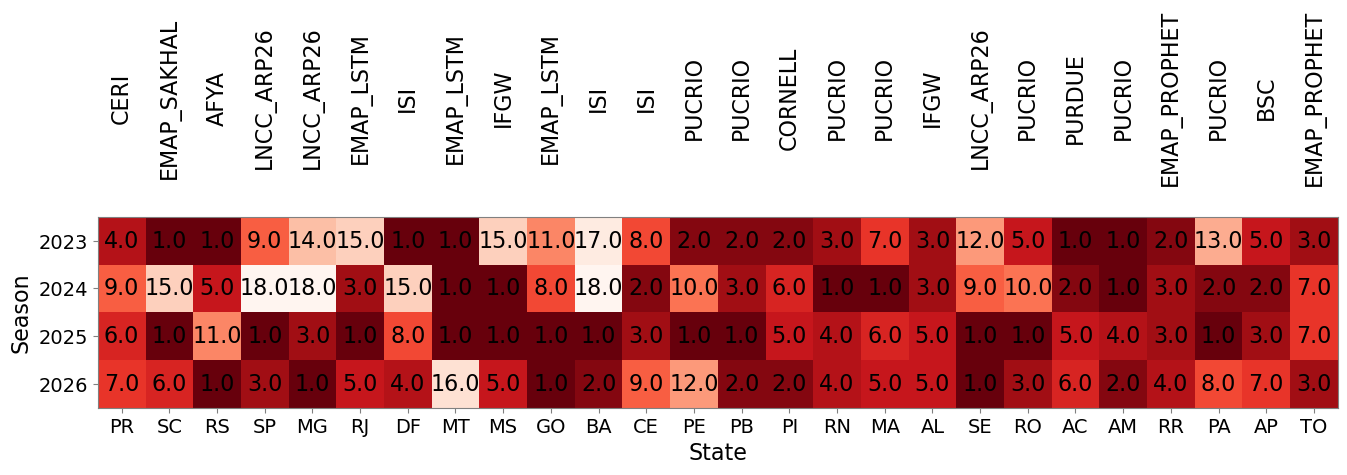

In [11]:
fig, ax = plt.subplots(figsize = (16, 3))

# Show as image
im = ax.imshow(df_pv.values, cmap="Reds_r")

# Add labels
ax.set_xticks(np.arange(df_pv.shape[1]))
ax.set_yticks(np.arange(df_pv.shape[0]))
ax.set_xticklabels(df_pv.columns)
ax.set_yticklabels(df_pv.index)

for i in range(df_pv.shape[0]):
    for j in range(df_pv.shape[1]):
        text = ax.text(j, i, df_pv.iloc[i, j],
                       ha="center", va="center", color="black")

for j in range(df_pv.shape[1]):
    
    model = df_rank_by_model_st.loc[df_rank_by_model_st.state == df_pv.columns[j]].model.values[0]

    text = ax.text(j, -3, model,
                       ha="center", va="center", color="black", 
                       rotation=90)
        
ax.set_xlabel('State')
ax.set_ylabel('Season')

plt.savefig('figures/forecast_puzzle.png', dpi = 400, bbox_inches = 'tight')
plt.show()